# Interlude — Why the labels are forced: charged fields

Alice holds 100 dollars. Bob holds 370 shekels. Who is richer?

You cannot answer by comparing 100 with 370. The two numbers are written in different units, and the comparison only means something after you convert one of them with the exchange rate. Change the units of the shekel (as Israel did in 1985) and the number 370 becomes 0.37, but nobody got poorer.

This interlude turns that observation into one of the most influential ideas in physics. So far, our labels have lived on *edges*. Now we also put values on *vertices*, and ask how to compare a vertex with its neighbor. The answer is that **you can't, unless there is a label on the edge between them**. If every vertex is allowed its own convention, labels on edges are not an extra ingredient you may add: they are forced. For the circle group, those forced labels turn out to be electromagnetism.

**What you'll learn**

- What a *charged field* is, and why the naive difference between neighboring values is meaningless.
- The *covariant difference*, which compares correctly by converting first, and why it needs the labels.
- How the smoothest possible charged field "feels" the face products, even where it never touches a defect. On a grid this produces one of the most famous pictures in physics.

**Prerequisites:** chapter 1 (labelings, reframings, classes, consistent labelings). Chapter 0's "prices" make a guest appearance. No probability is needed.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from lgt import *
from lgt import viz

viz.use_style()
rng = np.random.default_rng(15)
G = U1()   # the circle: labels are angles theta, i.e. the unit complex numbers e^{i theta}

Throughout, the label group is the circle $U(1)$. A label is an angle $\theta$, which we also read as the unit complex number $e^{i\theta}$; multiplying labels adds angles. A reframing $h:V\to U(1)$ acts on labels as in chapter 1: $U(s\to t)\mapsto h(s)\,U(s\to t)\,h(t)^{-1}$.

## I.1 Values at vertices

A **charged field** (glossary 3.9) is a function

$$
\psi:V\to\mathbb C,
$$

one complex number per vertex, written in that vertex's own convention. Changing conventions with a reframing $h$ changes the field as

$$
\psi(v)\longmapsto h(v)^{-1}\,\psi(v).
$$

For currencies: $\psi(v)$ is an amount of money held in currency $v$. If the new unit of $v$ is worth $h(v)$ old units, the same holding is described by the number $\psi(v)/h(v)$. For the circle, $h(v)^{-1}=e^{-ih(v)}$ rotates the complex number $\psi(v)$ by the angle $-h(v)$; its size $|\psi(v)|$ never changes.

A reframing is **global** if $h$ is the same at every vertex, and **local** otherwise. Here is the problem in one line of code: the naive difference between two neighbors survives global reframings, but not local ones.

In [2]:
B = Board.grid(4, 4)
psi = np.exp(1j * rng.uniform(0, 2 * np.pi, B.n_vertices))     # a charged field with |psi| = 1
s, t = B.edges[0]
def naive(psi): return abs(psi[t] - psi[s])

h_global = np.full(B.n_vertices, 0.9)                          # same angle everywhere
h_local = random_reframing(G, B, rng)                          # a different angle at each vertex
print(f"naive |psi(t) - psi(s)|      : {naive(psi):.4f}")
print(f"after a global reframing     : {naive(np.exp(-1j * h_global) * psi):.4f}")
print(f"after a local reframing      : {naive(np.exp(-1j * h_local) * psi):.4f}")

naive |psi(t) - psi(s)|      : 0.7542
after a global reframing     : 0.7542
after a local reframing      : 1.5454


> **Fact I.1 (naive differences are meaningless).** The size of the naive difference $|\psi(t)-\psi(s)|$ is unchanged by global reframings, but not by local ones. So if each vertex may choose its own convention, "how different are the values at $s$ and $t$?" has no answer yet.

> **Recap.** A charged field $\psi:V\to\mathbb C$ puts a value at each vertex in that vertex's convention, and reframings act by $\psi(v)\mapsto h(v)^{-1}\psi(v)$. Naive differences of neighbors depend on the conventions.

**Check yourself**

1. Which single number about $\psi(v)$ is unchanged by every reframing, for the circle group?

<details><summary>Answer</summary>

Its size $|\psi(v)|$, because reframing multiplies by a unit complex number. Everything else about a single value (its angle on the circle) is a matter of convention.

</details>

2. Why does a global reframing preserve $|\psi(t)-\psi(s)|$?

<details><summary>Answer</summary>

Both values are multiplied by the same $e^{-ic}$, so the difference is too, and $|e^{-ic}|=1$.

</details>

## I.2 Convert, then compare: the labels are forced

The fix is the one you already use for money: convert, then compare. If the edge carries a label $U(s\to t)$ that converts $s$'s convention into $t$'s, define the **covariant difference** (glossary 3.10)

$$
D_U\psi(s\to t)=\psi(s)\,U(s\to t)-\psi(t)\in\mathbb C .
$$

Reframe the labels *and* the field together. The label becomes $h(s)\,U\,h(t)^{-1}$ and the values become $h(s)^{-1}\psi(s)$ and $h(t)^{-1}\psi(t)$, so

$$
h(s)^{-1}\psi(s)\cdot h(s)\,U\,h(t)^{-1}-h(t)^{-1}\psi(t)=\big(\psi(s)\,U-\psi(t)\big)\,h(t)^{-1}.
$$

The $h(s)$ cancels, exactly as in chapter 1's telescoping. What remains is the old covariant difference times $h(t)^{-1}$, which has size 1.

> **Fact I.2 (comparing needs labels).** Under a joint reframing of $(U,\psi)$, every covariant difference is multiplied by a unit complex number, so $|D_U\psi(s\to t)|$ is an invariant. Comparing values at two vertices in a way that survives local reframings *requires* a label on the edge between them.

That is the whole argument. Physicists call it the **gauge principle**: demand that each point may choose its own convention, and you are forced to introduce labels on edges (a "gauge field") to compare neighbors. We started from the labels in chapter 1; here they appear as the price of comparing.

In [3]:
U = random_labeling(G, B, rng)
def cov_diff(U, psi):
    s, t = B.edges[:, 0], B.edges[:, 1]
    return psi[s] * np.exp(1j * U) - psi[t]

h = random_reframing(G, B, rng)
U2, psi2 = reframe(G, B, U, h), np.exp(-1j * h) * psi
print("labels changed:     ", not np.allclose(U, U2))
print("field changed:      ", not np.allclose(psi, psi2))
print("|covariant diffs| unchanged:", np.allclose(abs(cov_diff(U, psi)), abs(cov_diff(U2, psi2))))

labels changed:      True
field changed:       True
|covariant diffs| unchanged: True


A picture makes the bookkeeping visible. Below, the field is drawn as a clock at each vertex and the labels as clocks on the edges. The edge width shows $|D_U\psi|$. After a random joint reframing every clock has turned, but every width is the same.

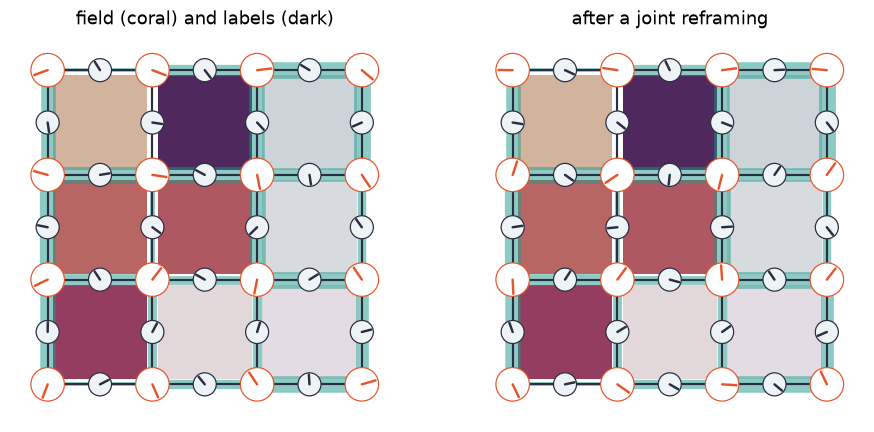

In [4]:
def draw_charged(ax, U, psi, title):
    widths = abs(cov_diff(U, psi))
    viz.draw_board(ax, B, U, G, faces=True, show_arrows=False, title=title)
    for e, (a, b) in enumerate(B.edges):
        (x0, y0), (x1, y1) = B.pos[[a, b]]
        ax.plot([x0, x1], [y0, y1], color=viz.TEAL, lw=1 + 5 * widths[e], alpha=0.5, zorder=2)
    for v in range(B.n_vertices):
        viz.draw_clock(ax, B.pos[v], np.angle(psi[v]), r=0.16, color=viz.CORAL, face="white", zorder=11)

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
draw_charged(axs[0], U, psi, "field (coral) and labels (dark)")
draw_charged(axs[1], U2, psi2, "after a joint reframing")
plt.show()

Every coral and dark clock has moved; the teal widths and the face colors have not. The widths, the face products, and anything built from them are the invariants of the pair $(U,\psi)$.

> **Recap.** The covariant difference $D_U\psi(s\to t)=\psi(s)U(s\to t)-\psi(t)$ converts, then compares. Its size is invariant under joint reframings, and it needs the edge label: local conventions force labels on edges.

**Check yourself**

1. If $U$ is the identity labeling, what is $D_U\psi$?

<details><summary>Answer</summary>

The naive difference $\psi(s)-\psi(t)$. The naive difference *is* a covariant difference, for the special (and convention-dependent) choice of all labels equal to 1.

</details>

2. In currency terms, what is $D_U\psi(s\to t)$?

<details><summary>Answer</summary>

Alice's holding at $s$, converted into $t$'s currency at the market rate, minus Bob's holding at $t$. A meaningful answer to "who is richer?", in $t$'s units.

</details>

## I.3 The smoothest charged field

Add up the squared covariant differences over all edges. This is the **smoothness cost** of the field:

$$
Q_U(\psi)=\sum_{e}\big|D_U\psi(e)\big|^2=\psi^{*}L_U\,\psi,
$$

where $L_U$ is a Hermitian $|V|\times|V|$ matrix, the **covariant Laplacian** (glossary 3.11). Expanding $|\psi(s)u-\psi(t)|^2$ with $u=U(s\to t)$ shows how to build it: each edge adds $1$ to the two diagonal entries $(s,s)$ and $(t,t)$, $-u$ at $(t,s)$ and $-\bar u$ at $(s,t)$. For the identity labeling it is the ordinary graph Laplacian.

In [5]:
def cov_laplacian(board, U):
    L = np.zeros((board.n_vertices, board.n_vertices), dtype=complex)
    for e, (s, t) in enumerate(board.edges):
        u = np.exp(1j * U[e])
        L[s, s] += 1; L[t, t] += 1
        L[t, s] -= u; L[s, t] -= np.conj(u)
    return L

L = cov_laplacian(B, U)
print("smoothness cost two ways:", np.isclose(np.sum(abs(cov_diff(U, psi)) ** 2), np.real(psi.conj() @ L @ psi)))

smoothness cost two ways: True


How smooth can a charged field be? Fix its overall size, $\sum_v|\psi(v)|^2=1$. The smallest possible cost is the smallest eigenvalue $\lambda_0(U)$ of $L_U$, and the minimizer is the corresponding eigenvector (linear algebra: the minimum of a Hermitian quadratic form on the unit sphere).

> **Fact I.3 (the spectrum only sees the class).** If $U'$ is a reframing of $U$ by $h$, then $L_{U'}=D^{*}L_UD$ with $D=\operatorname{diag}(h(v))$, a unitary matrix. So $L_U$ and $L_{U'}$ have the same eigenvalues: the whole spectrum is an invariant.

> **Fact I.4 (zero cost means consistent).** On a connected board, $\lambda_0(U)=0$ if and only if $U$ is consistent. The zero-cost field is then the reframing that turns $U$ into the identity labeling: chapter 0's *prices*, now as a vertex field.

*Why:* a zero-cost field has $\psi(t)=\psi(s)\,U(s\to t)$ along every edge, so $|\psi|$ is constant and $\psi$ converts consistently around every loop, which forces every loop product to be 1. Conversely, a consistent $U$ is a reframing of the identity labeling, whose constant field costs 0.

In [6]:
consistent = reframe(G, B, identity_labeling(G, B), random_reframing(G, B, rng))
for name, X in [("a random labeling", U), ("the same labeling, reframed", reframe(G, B, U, h)),
                ("a consistent labeling", consistent)]:
    lam = np.linalg.eigvalsh(cov_laplacian(B, X))
    print(f"{name:>28}: smallest eigenvalues {np.round(lam[:3], 4)}")

           a random labeling: smallest eigenvalues [0.2316 0.4845 0.7438]
 the same labeling, reframed: smallest eigenvalues [0.2316 0.4845 0.7438]
       a consistent labeling: smallest eigenvalues [0.     0.5858 0.5858]


The random labeling and its reframing have identical spectra (Fact I.3), and only the consistent labeling admits a field of zero cost (Fact I.4). So $\lambda_0(U)$ is a single number measuring *how far $U$ is from consistent*. Outside physics, this is the idea behind the spectral method for *angular synchronization*, which estimates unknown angles from noisy measurements of their differences: the eigenvector of $\lambda_0$ serves as the estimate.

> **Recap.** The smoothness cost of a charged field is $\psi^{*}L_U\psi$. The spectrum of the covariant Laplacian $L_U$ depends only on the class of $U$, and its smallest eigenvalue is 0 exactly when $U$ is consistent.

**Check yourself**

1. Why is every eigenvalue of $L_U$ at least 0?

<details><summary>Answer</summary>

$\psi^{*}L_U\psi$ is a sum of squared sizes, so it is never negative.

</details>

2. For the identity labeling, what is the zero-cost field?

<details><summary>Answer</summary>

Any constant field. For the ordinary graph Laplacian of a connected graph, the constants are exactly the eigenvectors with eigenvalue 0.

</details>

## I.4 Feeling a loop without touching a defect

Take the simplest board with a loop: a ring of $n$ vertices, with no faces at all. Every edge label is 1 except one, which is $e^{i\Phi}$. The loop product around the ring is $e^{i\Phi}$, and it is the only invariant (by chapter 1's tree normal form, the class of a ring labeling is determined by its loop product). Locally, every edge looks equally harmless: there is no face anywhere to be a defect.

Yet the charged field feels $\Phi$. Its smoothness spectrum is

$$
\lambda_k(\Phi)=2-2\cos\Big(\frac{2\pi k+\Phi}{n}\Big),\qquad k=0,1,\dots,n-1.
$$

To see why, number the vertices $0,\dots,n-1$ around the ring with edges $v\to v+1$, reframe the single $e^{i\Phi}$ into equal shares $e^{i\Phi/n}$ on every edge, and then try $\psi(v)=e^{-2\pi ikv/n}$.

In [7]:
n = 8
ring = Board.cycle(n, with_face=False)
Phis = np.linspace(0, 4 * np.pi, 241)
spec = []
for Phi in Phis:
    Ur = np.zeros(n); Ur[3] = Phi                       # one edge carries the whole loop product
    spec.append(np.linalg.eigvalsh(cov_laplacian(ring, Ur)))
spec = np.array(spec)
k = np.arange(n)
formula = np.sort(2 - 2 * np.cos((2 * np.pi * k[None, :] + Phis[:, None]) / n), axis=1)
print("matches the formula:", np.allclose(spec, formula))

matches the formula: True


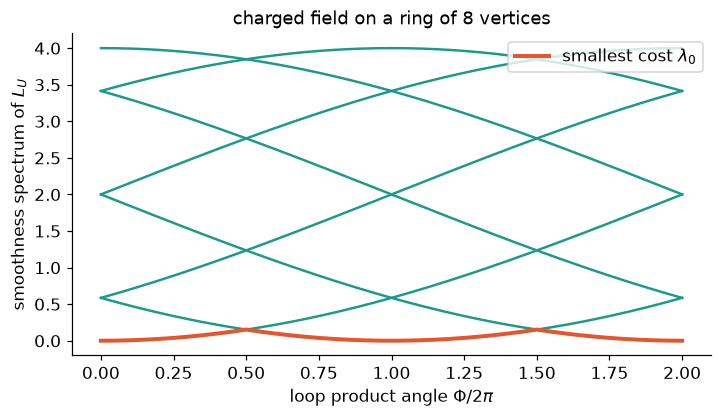

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(Phis / (2 * np.pi), spec, color=viz.TEAL, lw=1.6)
ax.plot(Phis / (2 * np.pi), spec[:, 0], color=viz.CORAL, lw=2.6, label=r"smallest cost $\lambda_0$")
ax.set(xlabel=r"loop product angle $\Phi/2\pi$", ylabel="smoothness spectrum of $L_U$",
       title=f"charged field on a ring of {n} vertices")
ax.legend(loc="upper right")
plt.show()

Every level moves as $\Phi$ changes, and the whole picture repeats when $\Phi$ goes once around the circle ($\Phi$ and $\Phi+2\pi$ are the same label). The smallest cost is 0 only when $\Phi$ is a multiple of $2\pi$: the consistent case of Fact I.4.

The charged field lives on vertices and the labels live on edges, but the loop product is a property of the ring as a whole, not of any single edge. Physicists know this as the **Aharonov–Bohm effect** (1959): an electron going around a thin tube of magnetic field is affected by it, even though the magnetic field is zero everywhere the electron can be. The tube is our $\Phi$; the electron's energy levels are our $\lambda_k$. In 1959 it was a surprise that the "potential" (our labels, up to reframing) carries physical information beyond the local fields. In our language it is no surprise at all: loop products are invariants, and nothing says they must be face products.

> **Recap.** On a ring with loop product $e^{i\Phi}$ and no defects anywhere, the smoothness spectrum still depends on $\Phi$, periodically with period $2\pi$. Physicists call this the Aharonov–Bohm effect.

**Check yourself**

1. Moving the special label $e^{i\Phi}$ to a different edge: does the spectrum change?

<details><summary>Answer</summary>

No. The new labeling has the same loop product, so it is in the same class (a reframing moves it), and Fact I.3 says the spectrum only sees the class.

</details>

2. At $\Phi=\pi$ the two lowest levels touch. Why might you expect that from symmetry?

<details><summary>Answer</summary>

At $\Phi=\pi$ the loop product is $-1$, which equals its own inverse. Walking the ring backwards gives the same class, and that mirror symmetry pairs up levels $k$ and $-1-k$ (mod $n$), whose formulas coincide. For $k=0$ it pairs the two lowest levels, $k=0$ and $k=n-1$.

</details>

## I.5 The butterfly

Now let every face carry the *same* defect. On an $L\times L$ torus, choose a labeling whose every face product is $e^{i\alpha}$. Chapter 1 showed that on a torus the product of all face products is the identity. So $L^2\alpha$ must be a multiple of $2\pi$, and $\alpha$ can only take the values $2\pi m/L^2$. Then ask the question of section I.3: what are the possible smoothness costs of a charged field?

One labeling that does the job: vertical labels $e^{i\alpha x}$ in column $x$, and horizontal labels 1, except that the wrap-around edge from the last column back to column 0 in row $y$ carries $e^{-i\alpha Ly}$. Any other labeling with the same face products differs from this one by a reframing and by the loop products around the torus's two directions (chapter 1, section 7). We simply pick this one.

In [9]:
def uniform_defect(Lside, m):
    """Torus labeling with every face product exp(2 pi i m / L^2)."""
    T = Board.grid(Lside, Lside, periodic=True)
    a, Uu = 2 * np.pi * m / Lside ** 2, np.zeros(T.n_edges)
    for (v, mu), e in T.meta["edge_index"].items():
        x, y = T.meta["coord"][v]
        if mu == 1:
            Uu[e] = a * x
        elif x == Lside - 1:
            Uu[e] = -a * Lside * y                       # the wrap-around column closes the books
    return T, Uu

T, Uu = uniform_defect(6, 5)
print("every face product equal:", np.allclose(np.mod(face_products(G, T, Uu), 2 * np.pi), 2 * np.pi * 5 / 36))

every face product equal: True


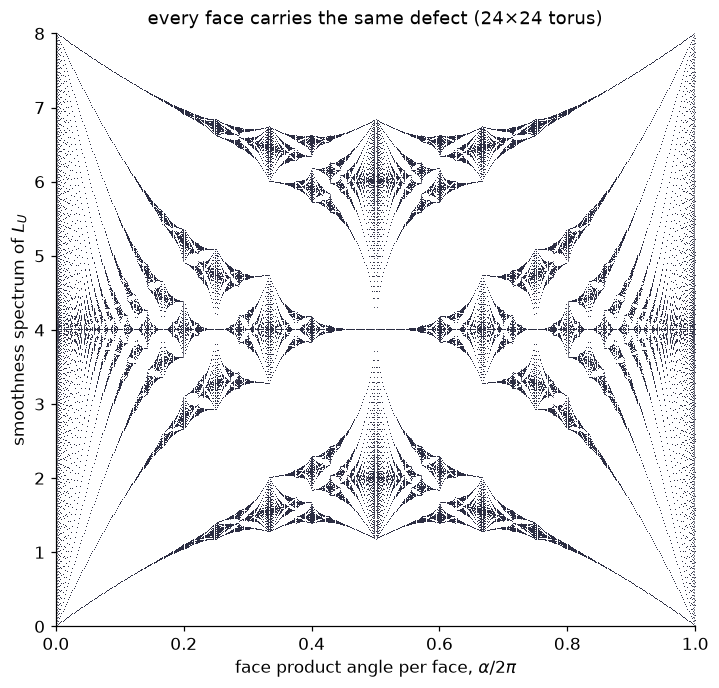

In [10]:
Lside = 24
alphas, levels = [], []
for m in range(0, Lside ** 2 + 1):
    T, Uu = uniform_defect(Lside, m)
    alphas.append(m / Lside ** 2)
    levels.append(np.linalg.eigvalsh(cov_laplacian(T, Uu)))
fig, ax = plt.subplots(figsize=(7.5, 7))
for a_, lev in zip(alphas, levels):
    ax.plot(np.full_like(lev, a_), lev, ",", color=viz.INK, alpha=0.6)
ax.set(xlabel=r"face product angle per face, $\alpha/2\pi$", ylabel="smoothness spectrum of $L_U$",
       title=rf"every face carries the same defect ({Lside}$\times${Lside} torus)", xlim=(0, 1), ylim=(0, 8))
plt.show()

Each vertical column of dots is the full spectrum of one $576\times576$ matrix, for one value of the common face angle. At $\alpha=0$ (left edge) the labeling is consistent and the spectrum fills a single band from 0 to 8. As $\alpha$ grows the band shatters: it splits into sub-bands with gaps, and the pattern of gaps repeats inside itself at every scale (look near $\alpha/2\pi=1/3$, $1/4$, $2/5$). This is **Hofstadter's butterfly** (1976): the energy levels (up to a constant shift) of an electron hopping on a square crystal in a uniform magnetic field. It is often cited as one of the first fractals found in physics, and experimental signatures of it were reported in 2013, in graphene stacked on boron nitride.

Everything in this picture came from one question: *how smooth can a charged field be, if every face has the same defect?*

> **Recap.** On a torus, every face can carry the same face product $e^{i\alpha}$ only for $\alpha\in\frac{2\pi}{L^2}\mathbb Z$. The smoothness spectrum, plotted against $\alpha$, is a fractal: Hofstadter's butterfly.

**Check yourself**

1. Why is the picture symmetric about $\alpha/2\pi=1/2$?

<details><summary>Answer</summary>

The labelings with face angles $\alpha$ and $-\alpha\equiv2\pi-\alpha$ are complex conjugates of each other, and $L_{\bar U}=\overline{L_U}$ has the same (real) eigenvalues.

</details>

2. Why must the smallest level be above 0 for every $0<\alpha<2\pi$?

<details><summary>Answer</summary>

Each such labeling has defects, so it is not consistent, and Fact I.4 says only consistent labelings admit a zero-cost field.

</details>

## I.6 What this has to do with electromagnetism

Everything above was about labels on a board and values at its vertices. Here is the physicists' reading, which you can now check line by line.

- The **circle group** $U(1)$ is the group of phases of a quantum wavefunction. A charged particle's wavefunction is our charged field $\psi$, and multiplying it by a phase at each point separately is a local reframing.
- Demanding that physics not depend on that local choice is the **gauge principle**. It forces a label on every edge, that is, a connection: the **electromagnetic potential** $A$, with $U(x\to x+\varepsilon e_\mu)=e^{i\varepsilon A_\mu(x)}$.
- The covariant difference is the **covariant derivative** $(\partial_\mu-iA_\mu)\psi$, the only way a charged particle can "feel" $A$ (minimal coupling).
- **Face angles are magnetic flux**: the angle of a face product is the flux of the magnetic field through that face (times the particle's charge). Consistent labelings are "no magnetic field anywhere".
- The covariant Laplacian is the **energy of a charged particle hopping on a grid in a magnetic field**. Section I.4 is the Aharonov–Bohm effect; section I.5 is the Hofstadter butterfly.
- The labels' *own* cost, the standard face cost $1-\cos\theta$ of chapter 2, becomes **Maxwell's energy** of the magnetic field for smooth labels (chapter 6, Fact 6.1, with no cross term because angles commute). Electric fields appear once the board has a time direction (chapter 5's layers).

Replace the circle by $SU(3)$ and the complex numbers by vectors in $\mathbb C^3$, and the same argument gives the strong force: the forced labels are the gluon field, and because $SU(3)$ does not commute, the labels' cost contains the cross term of chapter 6.

> **Recap.** Electromagnetism is what the gauge principle produces for the circle group: labels are the potential, face angles are magnetic flux, and the charged field's smoothness spectrum is the energy of a charged particle.

**Check yourself**

1. In this picture, what is a labeling with all face products equal to 1, but a nontrivial loop product around the torus?

<details><summary>Answer</summary>

Zero magnetic field everywhere, but a flux through the "hole" of the torus that no face can see: the torus version of the Aharonov–Bohm setup in section I.4.

</details>

## Interlude recap

- A **charged field** $\psi:V\to\mathbb C$ lives on vertices, in each vertex's convention, and reframes as $\psi(v)\mapsto h(v)^{-1}\psi(v)$.
- Naive differences of neighbors are convention-dependent. The **covariant difference** $\psi(s)U(s\to t)-\psi(t)$ converts, then compares, and its size is invariant. Labels on edges are forced: the gauge principle.
- The **covariant Laplacian** $L_U$ measures smoothness. Its spectrum depends only on the class of $U$, and its smallest eigenvalue vanishes exactly for consistent $U$.
- A ring's loop product shifts the spectrum though no face is a defect (Aharonov–Bohm). A uniform defect on every face produces a fractal spectrum (Hofstadter's butterfly).
- For the circle group this is electromagnetism: labels = potential, face angles = magnetic flux.

## Dictionary

| Our term | Other names |
|---|---|
| charged field $\psi$ | matter field, wavefunction of a charged particle; section of a bundle |
| global / local reframing | global / local (gauge) symmetry |
| covariant difference | covariant derivative, minimal coupling |
| "local conventions force labels" | the gauge principle (Weyl 1929; Yang and Mills 1954 for non-commuting groups) |
| covariant Laplacian $L_U$ | magnetic Laplacian; tight-binding Hamiltonian with Peierls phases; connection Laplacian |
| circle labels $e^{i\varepsilon A}$ | electromagnetic (vector) potential |
| face angle | magnetic flux through a face |
| ring loop product $\Phi$ | Aharonov–Bohm flux |
| spectrum vs uniform face angle | Hofstadter's butterfly |
| eigenvector of the smallest eigenvalue of $L_U$ | spectral method for angular synchronization |

## What's next

Chapter 2 puts probability on the labels: instead of one labeling, a whole distribution over labelings that favors few defects. The charged field returns in later chapters as the thing that "probes" a random labeling.